# 1. Avaliação independente do experimento
Selecione um experimento concluído. A leitura não cria treinamento e não altera seus artefatos.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from basket_price_prediction.config import ROOT, DATASET, SPLITS, FEATURES
from basket_price_prediction.data import load_data
from basket_price_prediction.preprocessing import prepare_monthly
from basket_price_prediction.features import build_supervised, temporal_split
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
import json
from IPython.display import Image
from basket_price_prediction.experiments import load_experiment, file_hash
from basket_price_prediction.evaluation import group_performance, calculate_metrics
from basket_price_prediction.config import RESULTS
completed=[p for p in RESULTS.iterdir() if p.is_dir() and (p/"manifest.json").exists() and json.loads((p/"manifest.json").read_text()).get("status")=="complete"]
if not completed: raise RuntimeError("Nenhum experimento concluído. Execute o treinamento no notebook 2.")
EXPERIMENT = sorted(completed)[-1]  # Substitua pelo caminho de uma execução para selecioná-la explicitamente.
exp=load_experiment(EXPERIMENT); test=exp["test"]; threshold=exp["config"]["selection"]["threshold"]
print("Experimento:",EXPERIMENT.name)
print("Família selecionada:",exp["config"]["selection"]["algorithm"],"| limiar:",threshold)

Experimento: 20261126_010701_449938_2a01bd42_comparacao
Família selecionada: random_forest | limiar: 0.25


## 2. Verificação da fonte, separação e modelo salvo
O hash verifica o arquivo de origem. A igualdade das probabilidades reconstruídas verifica o pipeline e as mesmas observações do teste.

In [2]:
assert file_hash(DATASET)==exp["manifest"]["dataset_sha256"], "A fonte mudou desde o treinamento"
monthly,_=prepare_monthly(load_data()); supervised,_=build_supervised(monthly); parts=temporal_split(supervised,SPLITS)
assert len(test)==len(parts["test"])
reloaded_probability=exp["model"].predict_proba(parts["test"][FEATURES])[:,1]
assert np.allclose(reloaded_probability,test.probability,rtol=1e-10,atol=1e-10)
assert test.target.tolist()==parts["test"].target.tolist()
print("Hash, registros, rótulos e probabilidades do modelo salvo conferem.")
display(pd.DataFrame(exp["summary"]["splits"]).T)

Hash, registros, rótulos e probabilidades do modelo salvo conferem.


,n,class_counts,first_target_month,last_target_month
train,10268,"{'0': 7200, '1': 3068}",2022-12-01,2024-12-01
validation,3554,"{'0': 2584, '1': 970}",2025-01-01,2025-08-01
test,3180,"{'0': 2261, '1': 919}",2025-09-01,2026-08-01


## 3. A comparação entre famílias
O gradient boosting obteve o maior F1 observado no teste (0,534), seguido pela random forest (0,517). A comparação entre famílias no teste é descritiva. Um intervalo para o F1 da random forest quantifica a incerteza da sua própria estimativa. Uma inferência sobre o ganho de uma família sobre outra exigiria um intervalo da diferença pareada, com as mesmas séries reamostradas. A random forest foi selecionada pelo desempenho na validação.

,algorithm,params,threshold,f1_validation,precision_validation,recall_validation,f1_test,precision_test,recall_test
3,random_forest,"{""class_weight"": null, ""max_depth"": 10, ""min_s...",0.25,0.517785,0.401821,0.727835,0.516896,0.392334,0.757345
1,gradient_boosting,"{""class_weight"": null, ""learning_rate"": 0.05}",0.25,0.474936,0.403902,0.576289,0.533922,0.423028,0.723613
0,decision_tree,"{""class_weight"": null, ""max_depth"": 10}",0.25,0.467943,0.392458,0.579381,0.492902,0.386518,0.680087
2,logistic_regression,"{""C"": 10.0, ""class_weight"": null}",0.25,0.439283,0.363208,0.555670,0.502516,0.390024,0.706202


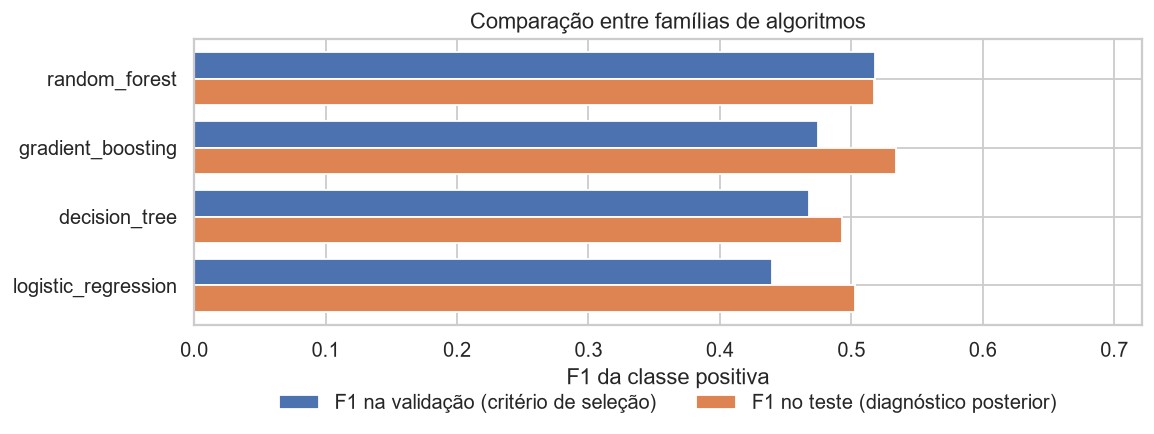

Amplitude descritiva do F1 de teste entre as quatro famílias: **0.041**.

In [3]:
comparacao=exp["comparison"].sort_values("f1_validation",ascending=False)
display(comparacao[["algorithm","params","threshold","f1_validation","precision_validation","recall_validation","f1_test","precision_test","recall_test"]])
display(Image(filename=str(EXPERIMENT/"figures"/"model_comparison.png")))
faixa=comparacao.f1_test.max()-comparacao.f1_test.min()
display(Markdown(f"Amplitude descritiva do F1 de teste entre as quatro famílias: **{faixa:.3f}**."))

## 4. Métricas, referências e intervalos de confiança
Precisão = VP/(VP+FP); recall = VP/(VP+FN); F1 combina as duas. Acurácia pode favorecer a classe majoritária. As referências são regras descritivas no mesmo teste, não classificadores treinados.

O bootstrap sorteia séries inteiras com reposição. Para cada diferença, modelo e referência são avaliados nas mesmas séries reamostradas. Dependência entre séries, como choques de preço comuns, permanece uma limitação.

In [4]:
planas=["test","validation_before_refit","reference_test_always_zero","reference_test_previous_increase"]
display(pd.DataFrame({k:exp["metrics"][k] for k in planas}).T)
print((EXPERIMENT/"reports"/"classification_report.txt").read_text())

,n,positives,negatives,accuracy,precision,recall,f1,balanced_accuracy,roc_auc,average_precision,brier_score,confusion_matrix,positive_prediction_rate
test,3180,919,2261,0.590881,0.392334,0.757345,0.516896,0.640282,0.714577,0.538269,0.178179,"[[1183, 1078], [223, 696]]",0.557862
validation_before_refit,3554,970,2584,0.629994,0.401821,0.727835,0.517785,0.660551,0.714822,0.501724,0.176035,"[[1533, 1051], [264, 706]]",0.494373
reference_test_always_zero,3180,919,2261,0.711006,0.0,0.0,0.0,0.5,0.5,0.288994,0.288994,"[[2261, 0], [919, 0]]",0.0
reference_test_previous_increase,3180,919,2261,0.557547,0.224605,0.21654,0.220499,0.456346,0.456346,0.275051,0.442453,"[[1574, 687], [720, 199]]",0.278616


               precision    recall  f1-score   support

Sem alta > 2%       0.84      0.52      0.65      2261
    Alta > 2%       0.39      0.76      0.52       919

     accuracy                           0.59      3180
    macro avg       0.62      0.64      0.58      3180
 weighted avg       0.71      0.59      0.61      3180



,IC 2.5%,mediana,IC 97.5%
precision,0.371,0.393,0.414
recall,0.725,0.757,0.790
f1,0.495,0.517,0.538
accuracy,0.571,0.591,0.611
balanced_accuracy,0.623,0.640,0.657
roc_auc,0.695,0.715,0.734
average_precision,0.506,0.539,0.571
brier_score,0.172,0.178,0.185
f1_gain_over_previous_increase,0.267,0.296,0.326
balanced_accuracy_gain_over_always_zero,0.123,0.140,0.157


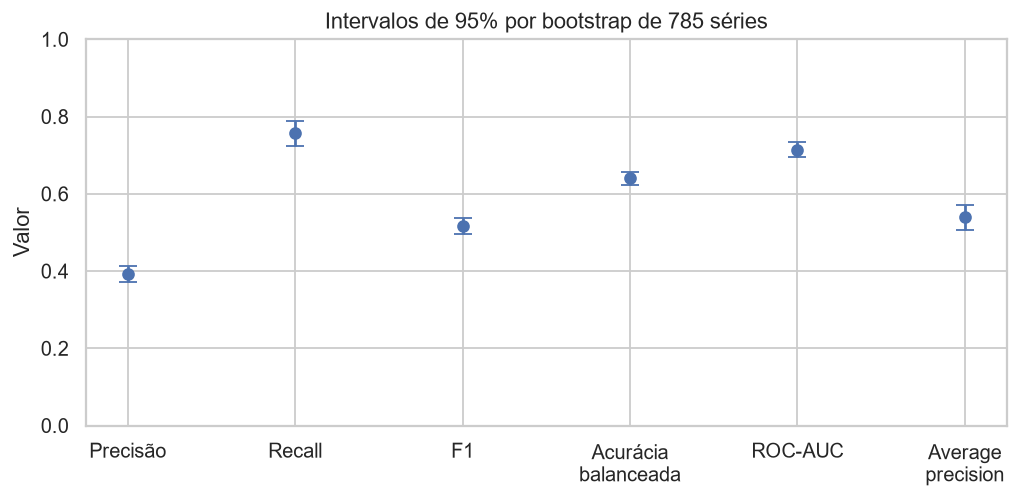

IC 95% do ganho de F1 sobre repetir a alta anterior: **[+0.267, +0.326]** — intervalo acima de zero.

IC 95% do ganho de acurácia balanceada sobre prever sempre sem alta: **[+0.123, +0.157]** — intervalo acima de zero.

Reamostragem de 785 séries, 2000 reamostras válidas.


In [5]:
ic=exp["metrics"]["test_confidence_intervals"]
tabela=pd.DataFrame(ic["intervals"]).T[["low","median","high"]]
tabela.columns=[f"IC {(1-ic['level'])/2:.1%}","mediana",f"IC {(1+ic['level'])/2:.1%}"]
display(tabela.round(3))
display(Image(filename=str(EXPERIMENT/"figures"/"metric_intervals.png")))
for nome,rotulo in [("f1_gain_over_previous_increase","ganho de F1 sobre repetir a alta anterior"),("balanced_accuracy_gain_over_always_zero","ganho de acurácia balanceada sobre prever sempre sem alta")]:
    faixa=ic["intervals"][nome]
    veredito = ("intervalo acima de zero" if faixa["low"] > 0 else
                "intervalo abaixo de zero" if faixa["high"] < 0 else "intervalo inclui zero")
    display(Markdown(f"IC {ic['level']:.0%} do {rotulo}: **[{faixa['low']:+.3f}, {faixa['high']:+.3f}]** — {veredito}."))
print("Reamostragem de %d séries, %d reamostras válidas." % (ic["series"],ic["samples"]))

## 5. Matriz de confusão, curvas e probabilidades
A curva precisão–recall deve ser comparada com a prevalência. ROC-AUC mede ordenação; Brier avalia probabilidades. A calibração em decis é descritiva e não garante calibração futura.

A curva de precisão e recall por limiar usa as predições do teste e descreve o desempenho retrospectivo. Uma revisão do limiar deve ser feita no desenvolvimento, com validação cronológica e um período reservado para avaliação.

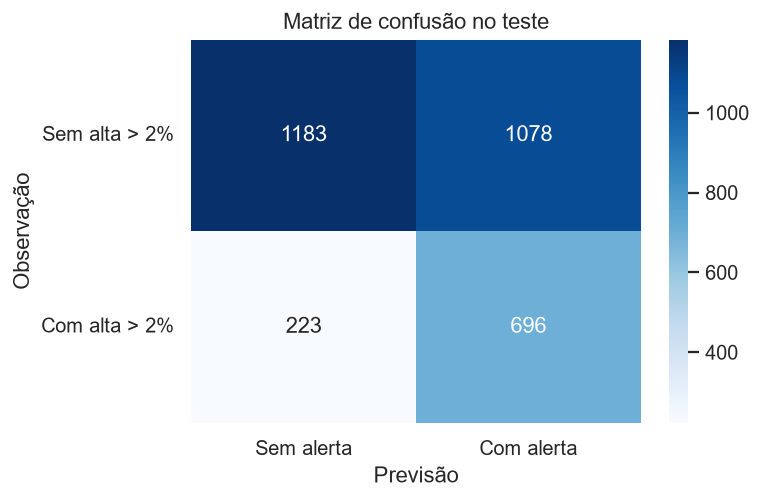

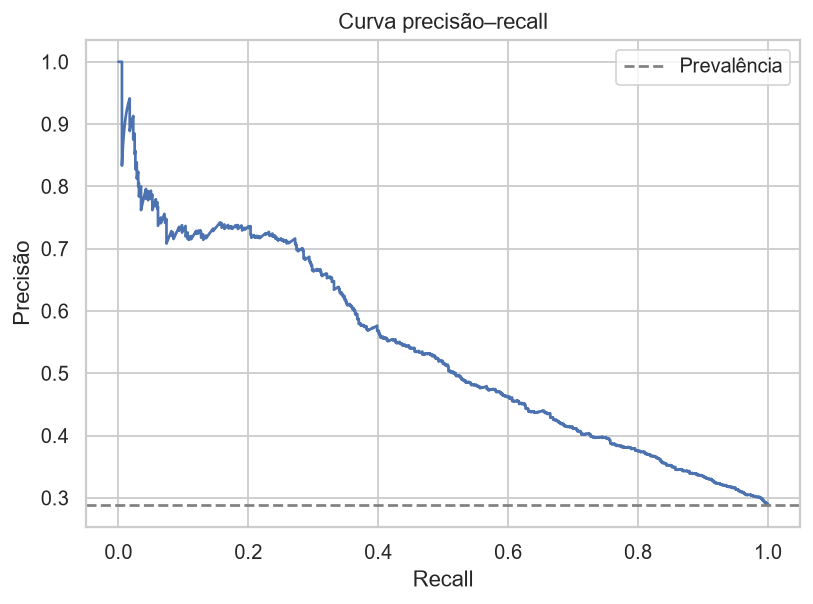

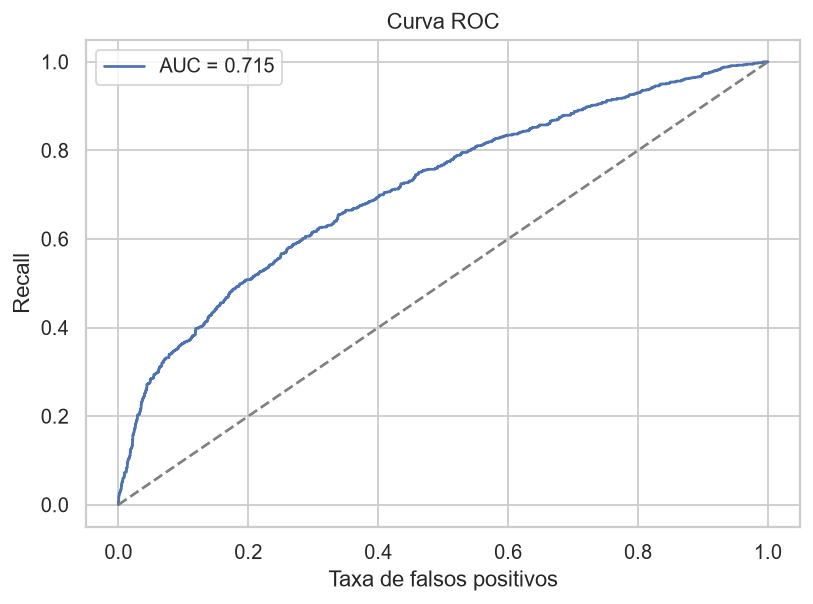

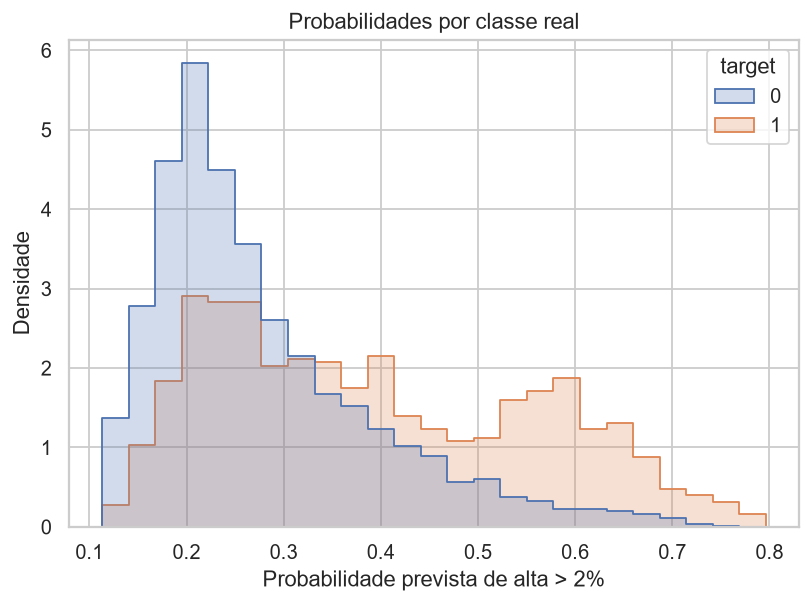

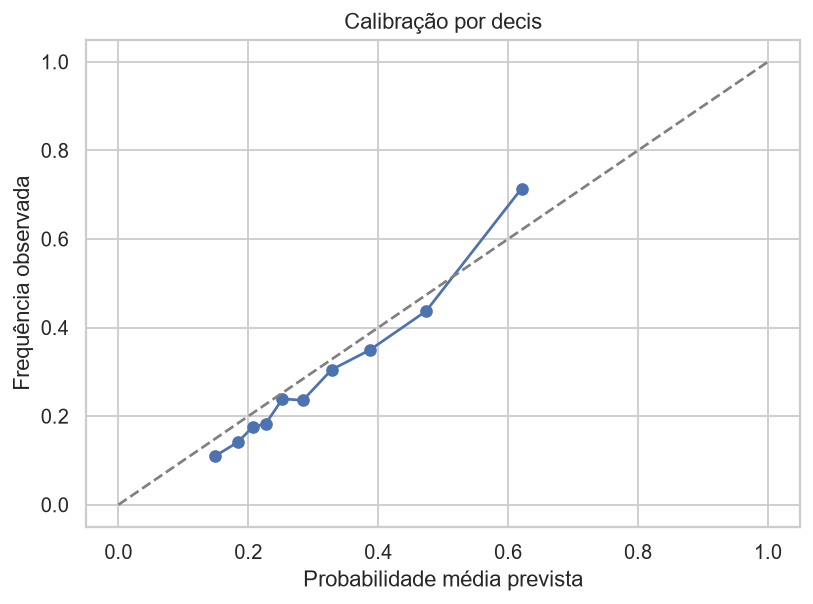

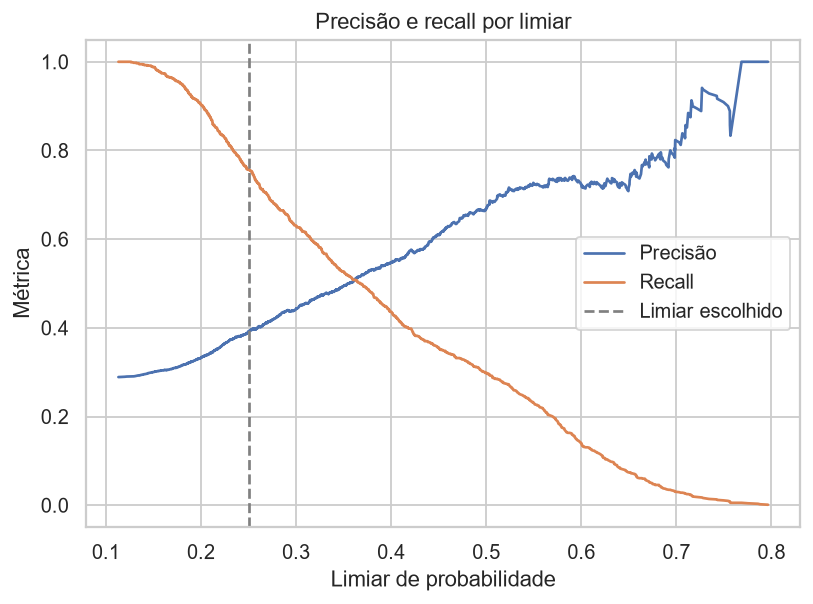

In [6]:
for name in ["confusion_matrix.png","precision_recall_curve.png","roc_curve.png","probability_distribution.png","calibration_curve.png","threshold_tradeoff.png"]:
    display(Image(filename=str(EXPERIMENT/"figures"/name)))

## 6. Desempenho temporal
Para cada mês-alvo são apresentados tamanho, positivos, precisão, recall, F1 e taxa prevista de positivos. Grupos sem positivos têm recall e F1 indefinidos. A ausência de data de coleta a partir de novembro/2025 limita a confirmação da disponibilidade real da informação na maior parte do teste.

,target_month,n,positives,precision,recall,f1,positive_prediction_rate
0,2025-09-01,406,104,0.365297,0.769231,0.495356,0.539409
1,2025-10-01,346,121,0.470588,0.793388,0.590769,0.589595
2,2025-11-01,313,96,0.385475,0.718750,0.501818,0.571885
3,2025-12-01,372,87,0.341121,0.839080,0.485050,0.575269
4,2026-01-01,388,100,0.345382,0.860000,0.492837,0.641753
5,2026-02-01,230,76,0.419580,0.789474,0.547945,0.621739
6,2026-03-01,157,59,0.379310,0.559322,0.452055,0.554140
7,2026-04-01,146,44,0.390805,0.772727,0.519084,0.595890
8,2026-05-01,120,39,0.557692,0.743590,0.637363,0.433333
9,2026-06-01,157,47,0.361446,0.638298,0.461538,0.528662


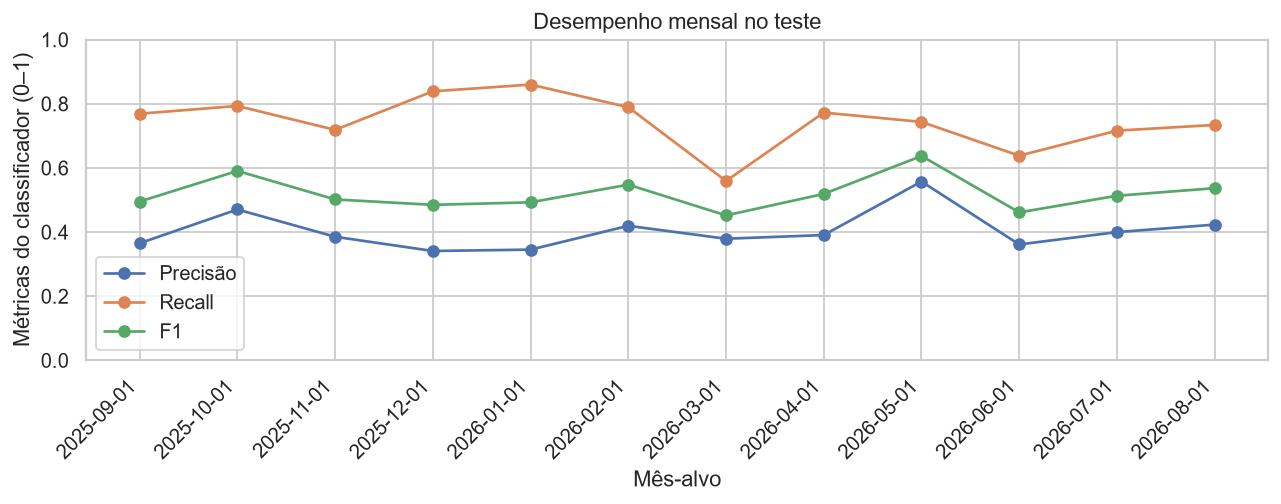

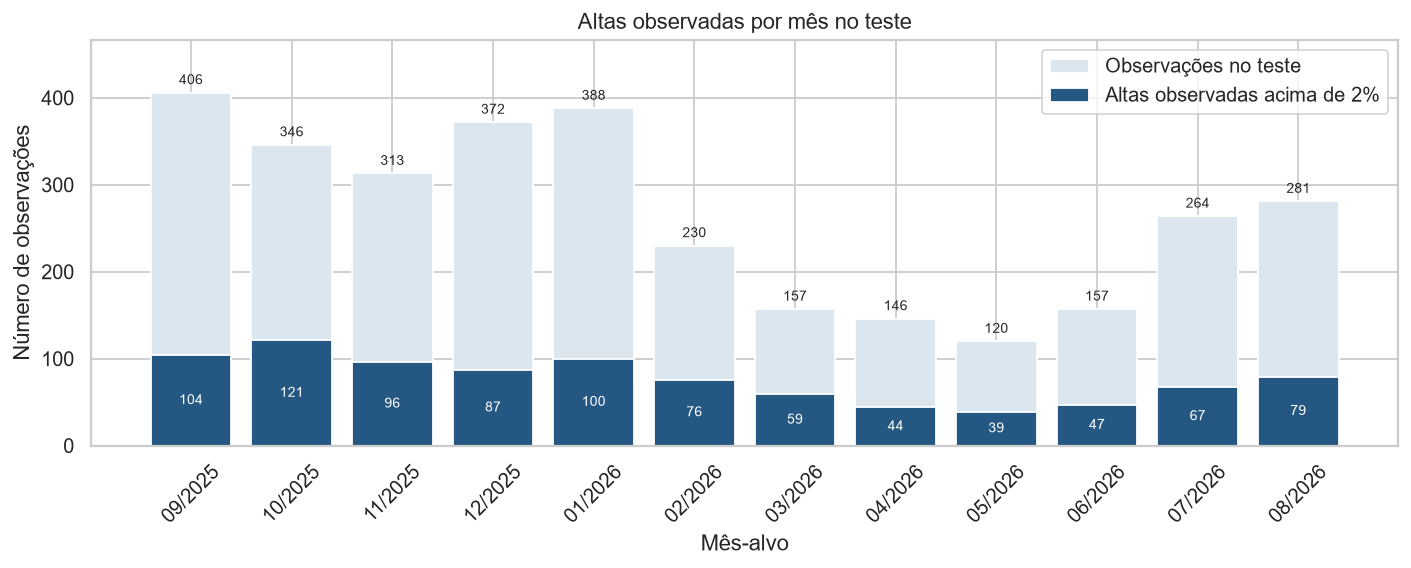

In [7]:
months=group_performance(test,"target_month",threshold).sort_values("target_month")
display(months[["target_month","n","positives","precision","recall","f1","positive_prediction_rate"]]); display(Image(filename=str(EXPERIMENT/"figures"/"monthly_performance.png")))
observed_figure = EXPERIMENT / "figures" / "monthly_observed_increases.png"
if observed_figure.exists():
    display(Image(filename=str(observed_figure)))

## 7. Produtos e supermercados
As tabelas incluem contagens, falsos positivos e falsos negativos. Para gráficos e rankings, exige-se pelo menos 30 observações; mesmo assim, diferenças podem ser instáveis e não foram ajustadas por incerteza ou multiplicidade.

,Produto,Exemplos,Altas reais,Precisão,Recall,F1,Falsos alertas,Altas sem alerta
10,Feijão,292,99,0.487500,0.393939,0.435754,41,60
5,Café,247,53,0.269841,0.962264,0.421488,138,2
13,Leite,238,68,0.388489,0.794118,0.521739,85,14
0,Arroz,217,49,0.272727,0.857143,0.413793,112,7
1,Açúcar,207,34,0.235294,0.823529,0.366013,91,6
20,Óleo,205,59,0.621622,0.389831,0.479167,14,36
15,Manteiga,201,51,0.430556,0.607843,0.504065,41,20
2,Banana Nanica,170,50,0.376000,0.940000,0.537143,78,3
4,Batata,170,72,0.432927,0.986111,0.601695,93,1
19,Tomate,168,73,0.464286,0.890411,0.610329,75,8


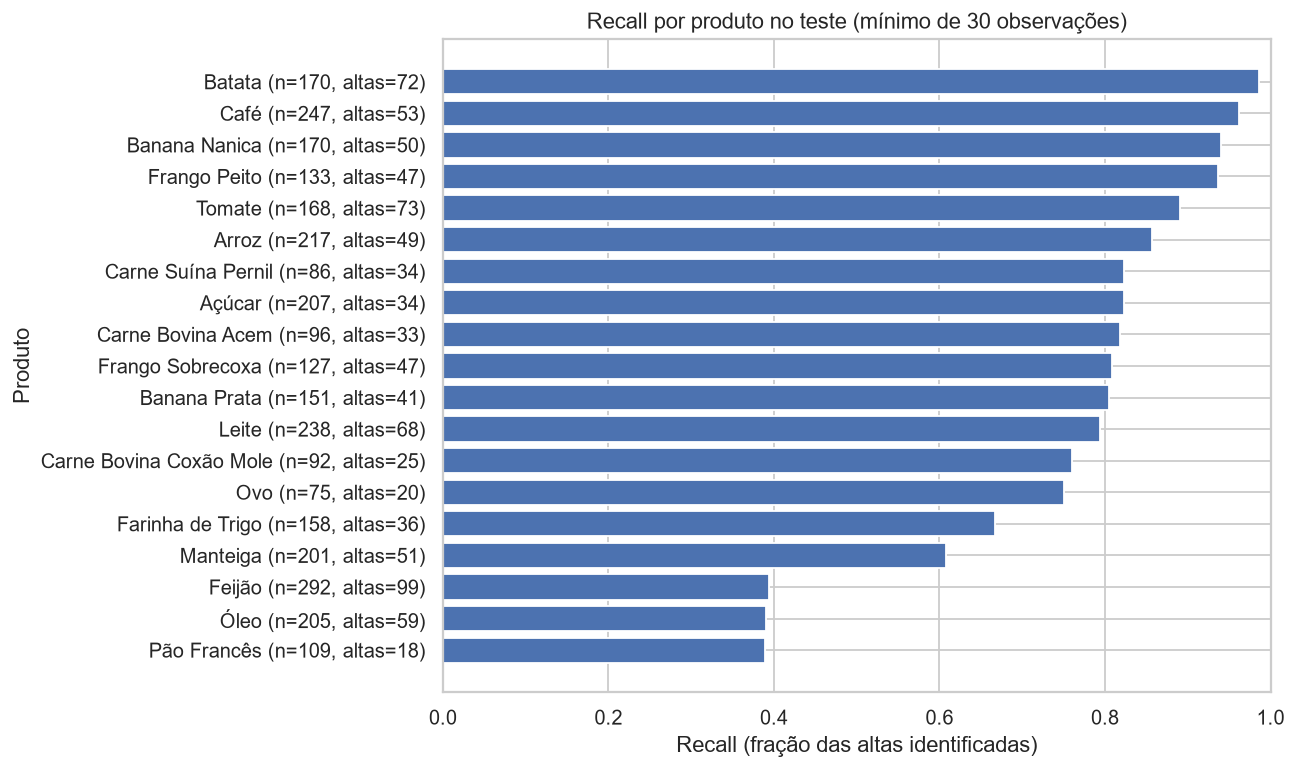

,Supermercado,Exemplos,Altas reais,Precisão,Recall,F1,Falsos alertas,Altas sem alerta
23,SUP_50,254,59,0.343750,0.559322,0.425806,63,26
12,SUP_27,242,57,0.446809,0.736842,0.556291,52,15
0,SUP_01,215,70,0.392157,0.857143,0.538117,93,10
10,SUP_22,210,60,0.391304,0.750000,0.514286,70,15
24,SUP_51,188,48,0.493827,0.833333,0.620155,41,8
21,SUP_43,186,59,0.398305,0.796610,0.531073,71,12
14,SUP_32,178,69,0.458716,0.724638,0.561798,59,19
1,SUP_04,167,66,0.455357,0.772727,0.573034,61,15
18,SUP_38,164,43,0.342466,0.581395,0.431034,48,18
5,SUP_15,142,32,0.377358,0.625000,0.470588,33,12


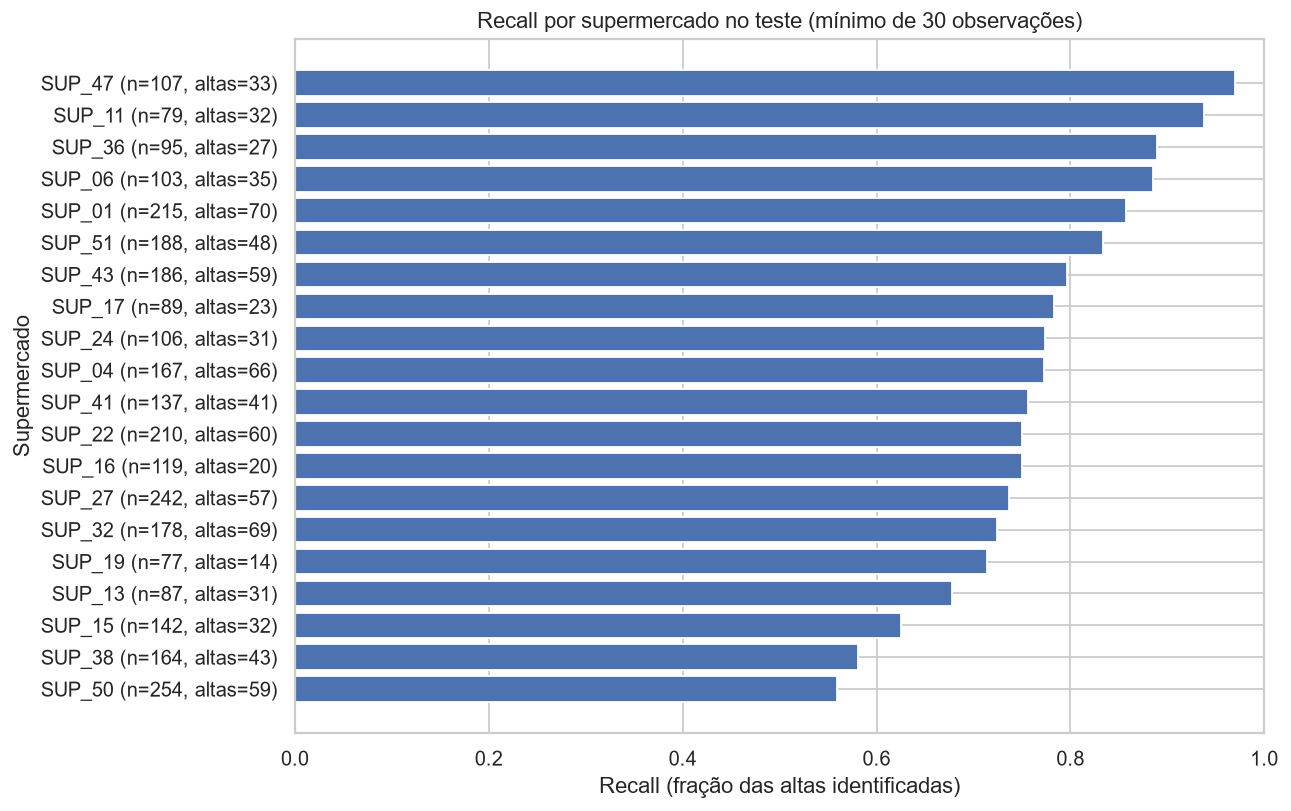

In [8]:
for col, label in [("product", "Produto"), ("supermarket", "Supermercado")]:
    groups = group_performance(test, col, threshold)
    columns = {col: label, "n": "Exemplos", "positives": "Altas reais",
               "precision": "Precisão", "recall": "Recall", "f1": "F1",
               "false_positives": "Falsos alertas", "false_negatives": "Altas sem alerta"}
    display(groups[list(columns)].sort_values("n", ascending=False).rename(columns=columns))
    display(Image(filename=str(EXPERIMENT/"figures"/f"{col}_performance.png")))

## 8. Análise de erros
Exemplos com identificadores, mês de previsão e alvo, variação observada, probabilidade e classes. Uma previsão positiva equivocada é falso alarme; uma negativa equivocada deixa de antecipar a alta.

In [9]:
for name in ["true_positive","true_negative","false_positive","false_negative"]:
    print(name); display(pd.read_csv(EXPERIMENT/"reports"/f"{name}_examples.csv").head(5))

true_positive


,supermarket,product,brand,quantity,month,target_month,price_current,variation_1m,actual_change,target,probability,prediction
0,SUP_17,Batata,(não informada),1,2025-09-01,2025-10-01,1.99,-0.429799,1.507538,1,0.796277,1
1,SUP_01,Batata,(não informada),1,2026-01-01,2026-02-01,1.99,-0.593047,1.407035,1,0.787884,1
2,SUP_43,Batata,(não informada),1,2025-09-01,2025-10-01,1.78,-0.402685,0.657303,1,0.785760,1
3,SUP_04,Batata,(não informada),1,2025-09-01,2025-10-01,2.29,-0.234114,0.131004,1,0.775208,1
4,SUP_30,Batata,(não informada),1,2025-08-01,2025-09-01,1.99,-0.601202,0.502513,1,0.768486,1


true_negative


,supermarket,product,brand,quantity,month,target_month,price_current,variation_1m,actual_change,target,probability,prediction
0,SUP_36,Óleo,Soya,0.9,2025-08-01,2025-09-01,7.59,0.041152,-0.408432,0,0.249911,0
1,SUP_47,Frango Sobrecoxa,(não informada),1.0,2025-11-01,2025-12-01,12.50,0.190476,0.000000,0,0.249866,0
2,SUP_24,Macarrão com Ovos,Galo,0.5,2026-06-01,2026-07-01,5.49,0.000000,-0.091075,0,0.249736,0
3,SUP_01,Arroz,Camil,5.0,2026-04-01,2026-05-01,19.49,-0.020111,0.005131,0,0.249735,0
4,SUP_36,Banana Prata,(não informada),1.0,2025-12-01,2026-01-01,12.90,0.434928,-0.193798,0,0.249566,0


false_positive


,supermarket,product,brand,quantity,month,target_month,price_current,variation_1m,actual_change,target,probability,prediction
0,SUP_17,Frango Sobrecoxa,(não informada),1,2025-11-01,2025-12-01,0.10,-0.994972,0.000000,0,0.756844,1
1,SUP_06,Batata,(não informada),1,2025-08-01,2025-09-01,1.95,-0.184100,0.015385,0,0.726039,1
2,SUP_43,Açúcar,União,1,2026-05-01,2026-06-01,3.45,-0.248366,-0.086957,0,0.714764,1
3,SUP_41,Tomate,(não informada),1,2025-11-01,2025-12-01,3.95,-0.329372,0.000000,0,0.711080,1
4,SUP_43,Leite,Parmalat,1,2025-12-01,2026-01-01,3.75,-0.157303,0.000000,0,0.709064,1


false_negative


,supermarket,product,brand,quantity,month,target_month,price_current,variation_1m,actual_change,target,probability,prediction
0,SUP_22,Café,Caboclo,0.5,2025-09-01,2025-10-01,34.99,0.002579,0.060303,1,0.248305,0
1,SUP_27,Açúcar,Caravelas,1.0,2025-09-01,2025-10-01,4.99,0.000000,0.060120,1,0.248128,0
2,SUP_04,Arroz,Camil,5.0,2026-02-01,2026-03-01,17.50,-0.019608,0.085143,1,0.247666,0
3,SUP_15,Ovo,(não informada),12.0,2026-05-01,2026-06-01,12.90,0.000000,0.077519,1,0.247626,0
4,SUP_04,Carne Bovina Acem,(não informada),1.0,2026-01-01,2026-02-01,39.99,0.000000,0.072768,1,0.247602,0


## 9. Interpretação: permutação, e não coeficientes
No treino, houve maior frequência de altas futuras após quedas acentuadas, menor frequência no grupo de preço inalterado e uma elevação modesta após variações de 2% a 5%. Esse perfil descreve uma associação nos dados e ajuda a motivar a comparação entre modelos lineares e árvores.

A importância por permutação mede a queda da *average precision* ao embaralhar cada atributo de entrada. Ela é comparável entre famílias, atua antes do one-hot e não depende da forma funcional do modelo.

Coeficientes não servem aqui. O diagnóstico de colinearidade mostra que `rolling_mean_3m` é, por construção, a média de `price_current`, `price_lag_1` e `price_lag_2` — uma combinação linear **exata**, com VIF infinito. A repartição de peso entre variáveis perfeitamente colineares é matematicamente indeterminada. A predição não é afetada; apenas a leitura atributo a atributo é.

Importância por permutação continua sendo associação, não causa: um atributo redundante pode mostrar importância baixa só porque outro carrega a mesma informação.

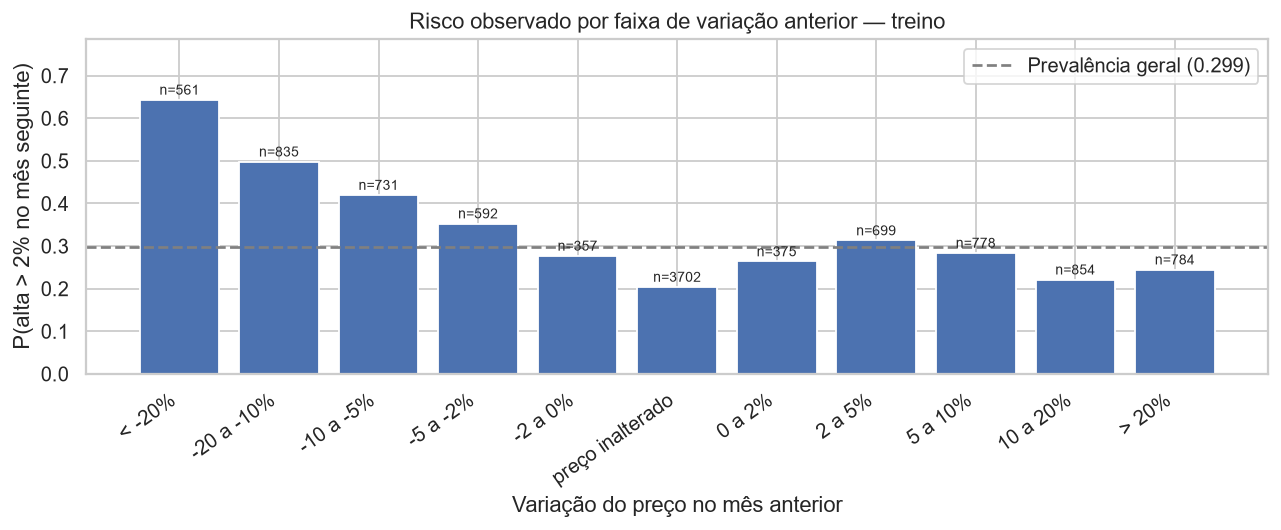

band,n,risk
< -20%,561,0.643
-20 a -10%,835,0.498
-10 a -5%,731,0.420
-5 a -2%,592,0.353
-2 a 0%,357,0.277
preço inalterado,3702,0.204
0 a 2%,375,0.264
2 a 5%,699,0.313
5 a 10%,778,0.284
10 a 20%,854,0.221


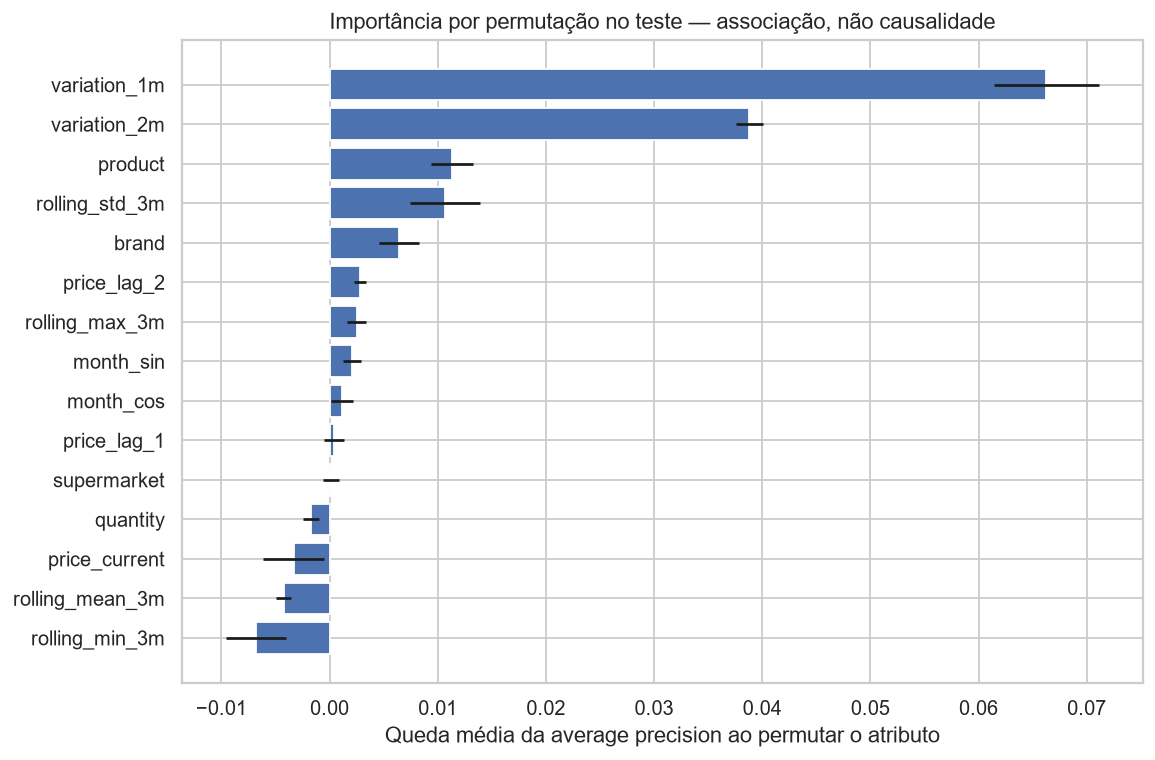

,feature,r2_vs_others,vif,max_abs_correlation,most_correlated_with
0,price_current,1.000,inf,0.990,rolling_max_3m
1,price_lag_1,1.000,inf,0.986,rolling_min_3m
2,price_lag_2,1.000,inf,0.986,rolling_min_3m
3,rolling_mean_3m,1.000,inf,0.980,price_lag_1
4,rolling_max_3m,1.000,5138.691,0.990,price_current
5,rolling_min_3m,1.000,3091.119,0.986,price_lag_1
6,rolling_std_3m,0.999,1116.841,0.893,variation_2m
7,variation_2m,0.966,29.610,0.945,variation_1m
8,variation_1m,0.960,25.291,0.945,variation_2m
9,month_cos,0.007,1.007,0.030,variation_2m


In [10]:
display(Image(filename=str(EXPERIMENT/"figures"/"risk_by_variation.png")))
display(exp["risk_profile"].style.format({"risk":"{:.3f}"}).hide(axis="index"))
display(Image(filename=str(EXPERIMENT/"figures"/"permutation_importance.png")))
display(exp["collinearity"].round(3))
if (EXPERIMENT/"figures"/"coefficients.png").exists():
    print("A família vencedora é linear; os coeficientes são exibidos apenas com a ressalva de colinearidade acima.")
    display(Image(filename=str(EXPERIMENT/"figures"/"coefficients.png")))

## 10. Limitações e resposta à questão
A amostra condiciona-se à continuidade de três meses de histórico e disponibilidade do alvo, podendo selecionar séries mais estáveis. Marcas ausentes podem misturar itens; unidades e descrições têm ambiguidades. A coleta posterior a outubro/2025 não tem data individual registrada, o que impede verificar sua disponibilidade efetiva em 10 dos 12 meses-alvo do teste. Inflação, custos, promoções e mudanças de coleta não estão explicitamente representados. Comparações por grupo são descritivas e não controlam multiplicidade; resultados não garantem movimentos futuros.

In [11]:
m=exp["metrics"]["test"]; cm=m["confusion_matrix"]
zero=exp["metrics"]["reference_test_always_zero"]; regra=exp["metrics"]["reference_test_previous_increase"]
intervalos = exp["metrics"]["test_confidence_intervals"]["intervals"]
ganho = intervalos["f1_gain_over_previous_increase"]
ganho_balanceado = intervalos["balanced_accuracy_gain_over_always_zero"]
f1=exp["metrics"]["test_confidence_intervals"]["intervals"]["f1"]
display(Markdown(
    f"Família selecionada: **{exp['config']['selection']['algorithm']}**, limiar {exp['config']['selection']['threshold']:.2f}.\n\n"
    f"No teste, o recall foi **{m['recall']:.1%}**, precisão **{m['precision']:.1%}**, F1 **{m['f1']:.3f}** (IC 95% [{f1['low']:.3f}, {f1['high']:.3f}]) "
    f"e precisão média **{m['average_precision']:.3f}** (prevalência {m['positives']/m['n']:.1%}). "
    f"Houve **{cm[0][1]} falsos positivos** e **{cm[1][0]} falsos negativos**: {cm[0][1]/(cm[0][1]+cm[1][1]):.1%} dos alertas foram falsos.\n\n"
    f"A referência sempre zero teve acurácia {zero['accuracy']:.1%} com recall zero; repetir a alta anterior teve F1 {regra['f1']:.3f}. "
    f"O IC 95% do ganho de F1 sobre repetir a alta anterior é **[{ganho['low']:+.3f}, {ganho['high']:+.3f}]**. "
    f"O IC 95% do ganho de acurácia balanceada sobre nunca alertar é **[{ganho_balanceado['low']:+.3f}, {ganho_balanceado['high']:+.3f}]**.\n\n"
    "Os intervalos quantificam os ganhos no teste retrospectivo sob o bootstrap por série. "
    "A frequência de falsos alertas limita o possível uso prático. O custo de cada tipo de erro permanece em aberto."))

Família selecionada: **random_forest**, limiar 0.25.

No teste, o recall foi **75.7%**, precisão **39.2%**, F1 **0.517** (IC 95% [0.495, 0.538]) e precisão média **0.538** (prevalência 28.9%). Houve **1078 falsos positivos** e **223 falsos negativos**: 60.8% dos alertas foram falsos.

A referência sempre zero teve acurácia 71.1% com recall zero; repetir a alta anterior teve F1 0.220. O IC 95% do ganho de F1 sobre repetir a alta anterior é **[+0.267, +0.326]**. O IC 95% do ganho de acurácia balanceada sobre nunca alertar é **[+0.123, +0.157]**.

Os intervalos quantificam os ganhos no teste retrospectivo sob o bootstrap por série. A frequência de falsos alertas limita o possível uso prático. O custo de cada tipo de erro permanece em aberto.